In [2]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
load_dotenv()

True

In [3]:
# step 1 :
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
chunks = text_splitter.split_documents(raw_docs)

print(len(chunks))


51


In [4]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)
vectorstore.add_documents(chunks)




/var/folders/fq/kr6gv5l17pd4j572n0_n3f2c0000gn/T/ipykernel_60480/3605738323.py:5: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(


['935c1bba-9426-4bb5-9c7a-364766cc420b',
 'cb1d8884-aad4-4883-b660-53b342ff4402',
 '716ffadd-c18c-478d-a4c9-c2ba8261d0fd',
 '307685ab-08eb-4508-9a13-a8eb243f8127',
 '42523e26-8ec5-4b32-aeaa-13c1a63cf436',
 '9ec4b69b-6a89-472d-a1fc-d3fbdcecd816',
 '53f59bbb-3357-4b73-be49-b903cb209bef',
 '8ff4fe1b-ca01-4439-a213-08ca2f69d40d',
 '5748c311-e096-4622-9a80-2c8852bc5725',
 'be73bb98-3443-4f58-9f21-a63b895b01c0',
 '2ade50a4-ac9a-45b8-8452-e09a48ceb0a1',
 'f7ba2a57-81d4-4d69-a2b0-e82075f0367d',
 'f6db1191-bb81-4a8f-937f-a85c5905ac98',
 '32b426f8-7fb2-4910-bc14-3d5eb6b69a6c',
 'cf7f2d6a-9f94-4110-903d-3a190674ad89',
 '44d84caf-1865-4f70-bf27-3f54c7b2fe66',
 '2da51efc-ac15-43da-a31b-d4b7a55abdd6',
 'e8323545-6785-459c-92cc-33a0a4aba172',
 '89a0add1-229a-465d-b702-04d26f81c761',
 '698c3a41-975b-4a69-ae9e-5c4785cc0c50',
 'f04eecf2-4d87-438f-b4ac-5e9ba7e6e432',
 '8cd467c9-c8a2-4156-8d74-b9f1cf8c7c17',
 '0b578ac0-d157-43fb-819d-d3f5dd5ec6ae',
 '70f5d0f0-bf00-47b0-9005-03632b60b35e',
 '6a9a2aa5-9d38-

In [16]:
# step 4 : retrieval

retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [6]:
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str | None
    generation: str
    needs_retrieval: bool


llm = ChatOpenAI(model="gpt-5-mini")

In [7]:
class RouteDecision(BaseModel):
    needs_retrieval: bool

    

In [11]:
def route_question(state: AgenticRAGState):
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    return {"needs_retrieval": decision.needs_retrieval}


def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    if docs:
        context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context}



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": context})
        return {"generation": response}
    else:
        print('inside else part')
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        chain = prompt_template | llm | StrOutputParser()
        response = chain.invoke({"query": query, "context": None})
        return {"generation": response}




In [13]:
from typing import Literal

def route_after_classification(state: AgenticRAGState) -> Literal["retrieve", "generate"]:
    return "retrieve" if state['needs_retrieval'] else "generate"


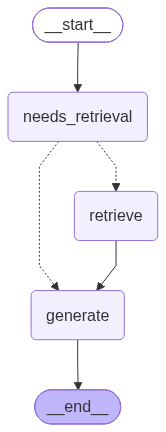

In [14]:
graph_builder = StateGraph(AgenticRAGState)
graph_builder.add_node("needs_retrieval", route_question)
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "needs_retrieval")
graph_builder.add_conditional_edges("needs_retrieval", route_after_classification)
graph_builder.add_edge("retrieve", "generate")

graph_builder.add_edge("generate", END)
graph = graph_builder.compile()
graph

In [17]:
# Query 1: domain-specific (should trigger retrieval)
domain_query = "What does the report say about EV adoption trajectories and oil demand displacement?"

result_domain = graph.invoke({"query": domain_query, "messages": []})

In [18]:
result_domain

{'messages': [],
 'query': 'What does the report say about EV adoption trajectories and oil demand displacement?',
 'retrieved_docs': [Document(metadata={'page': 7, 'creationdate': '2026-04-18T21:49:03+05:00', 'producer': 'ReportLab PDF Library - (opensource)', 'source': './documents/evs_oil_price_shock.pdf', 'title': '(anonymous)', 'trapped': '/False', 'subject': '(unspecified)', 'creator': '(unspecified)', 'page_label': '8', 'total_pages': 15, 'keywords': '', 'moddate': '2026-04-18T21:49:03+05:00', 'author': '(anonymous)'}, page_content='Will EVs Dampen the Oil Price Shock?\nVersion 1.0\nResearch Report — For Educational and RAG Pipeline Use\nPage 8\n4. EV Adoption Trajectories and Oil Demand Displacement\n Projecting oil demand displacement from EV adoption requires integrating three distinct\nanalytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing\nICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.\nTh

In [19]:
general_query = "What is the capital of India?"
result_general = graph.invoke({"query": general_query, "messages": [], "context": None})

inside else part


In [20]:
result_general

{'messages': [],
 'query': 'What is the capital of India?',
 'context': None,
 'generation': 'The capital of India is New Delhi. It serves as the seat of the central government and is part of the National Capital Territory of Delhi.',
 'needs_retrieval': False}

In [ ]:
# route_question(AgenticRAGState(query="who is prime minimiser of India"))

{'needs_retrieval': False}